To run in Google colab, create a new folder in files and name it *data*. Then, upload *pitchfork_discogs.csv* into it.

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import umap
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

In [42]:
pitch_disogs = "/content/data/pitchfork_discogs.csv"
review_df = df=pd.read_csv(pitch_disogs)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# Overall Dataset

In [43]:
review_df['reviewdate'] = pd.to_datetime(review_df['reviewdate'])

In [44]:
review_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10764 entries, 0 to 10763
Data columns (total 32 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   artist            10764 non-null  object        
 1   album             10764 non-null  object        
 2   reviewauthor      10764 non-null  object        
 3   score             10764 non-null  float64       
 4   releaseyear       10764 non-null  float64       
 5   reviewdate        10764 non-null  datetime64[ns]
 6   recordlabel       10756 non-null  object        
 7   genre             10764 non-null  object        
 8   danceability      10764 non-null  float64       
 9   energy            10764 non-null  float64       
 10  key               10764 non-null  float64       
 11  loudness          10764 non-null  float64       
 12  speechiness       10764 non-null  float64       
 13  acousticness      10764 non-null  float64       
 14  instrumentalness  1076

**This is a description of the important columns in the dataset:**

| column | meaning | values |
|---|---|---|
| `artist` | artist that released the album |
| `album` | album |
| `reviewauther` | Pitchfork reviewer that reviewed the album |
| `score` | Pitchfork score of the album given by the reviewer | [0.0, 10.0]
| `releaseyear` | the year that the album released |
| `reviewdate` | the date that the album was reviewed by Pitchfork |
| `recordlabel` | the record label that distributed the album|
| `genre` | the overall genre of the album |
| `danceability` | Spotify audio feature: how suitable a track is for dancing | [0.0, 1.0]
| `energy` | Spotify audio feature: perceptual measure of intensity and activity | [0.0, 1.0]
| `key` | Spotify audio feature: the key the track is in using standard pitch notation| {-1, 11} (-1 = no key detected)
| `loudness` | Spotify audio feature: overall loudness of a track in decibels (dB) | [-60.0, 0.0]
| `speechiness` | Spotify audio feature: presence of spoken words in a track | [0.0, 1.0]
| `acousticness` | Spotify audio feature: confidence measure of whether the track is acoustic | [0.0, 1.0]
| `instrumentalness` | Spotify audio feature: whether a track contains no vocals | [0.0, 1.0]
| `liveness` | Spotify audio feature: the presence of an audience in the recording | [0.0, 1.0]
| `valence` | Spotify audio feature: the musical positiveness conveyed by a track | [0.0, 1.0]
| `tempo` | Spotify audio feature: overall estimated tempo of a track in beats per minute (BPM) | [0.0, 200]
| `date` | the release date of the album on Discogs, used to match the albums |
| `rating_avg` | average Discogs user ratings of the album | [0.0, 5.0]
| `rating_count` | number of Discogs user ratings of the album |
| `have` | number of Discogs users who 'have' the album |
| `want` | number of Discogs users who 'want' the album |
| `match_quality` | score used to match Discogs data with Pitchfork data |

Columns after match quality are values obtained while scraping the Discogs data and matching Discogs data to Pitchfork data.

This is an overall description of the numerical data we will be looking at.

In [45]:
cols = [
    'releaseyear',
    'score',
    'rating_avg',
    'rating_count',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]
review_df[cols].describe().round(3)

,releaseyear,score,rating_avg,rating_count,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
count,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000,10764.000
mean,2010.160,7.029,4.174,75.061,0.502,0.607,5.221,-9.277,0.087,0.297,0.300,0.193,0.396,120.527
std,5.317,1.252,0.313,184.586,0.156,0.204,1.595,4.313,0.083,0.261,0.305,0.092,0.181,15.327
min,1998.000,0.000,1.500,10.000,0.060,0.000,0.000,-51.729,0.011,0.000,0.000,0.021,0.000,24.708
25%,2006.000,6.500,4.000,18.000,0.399,0.476,4.350,-11.208,0.041,0.087,0.019,0.134,0.258,111.423
50%,2010.000,7.300,4.200,34.000,0.503,0.631,5.250,-8.427,0.056,0.221,0.181,0.174,0.394,120.481
75%,2015.000,7.800,4.390,73.000,0.612,0.759,6.111,-6.327,0.094,0.457,0.559,0.227,0.524,129.237
max,2019.000,10.000,5.000,9667.000,0.974,0.998,11.000,1.984,0.950,0.995,0.982,0.978,0.969,199.958


## EDA Pitchfork Scores

In this section, we will explore the Pitchfork dataset.

### Overall Pitchfork Score statistics

We will begin by looking at the Pitchfork score distribution.

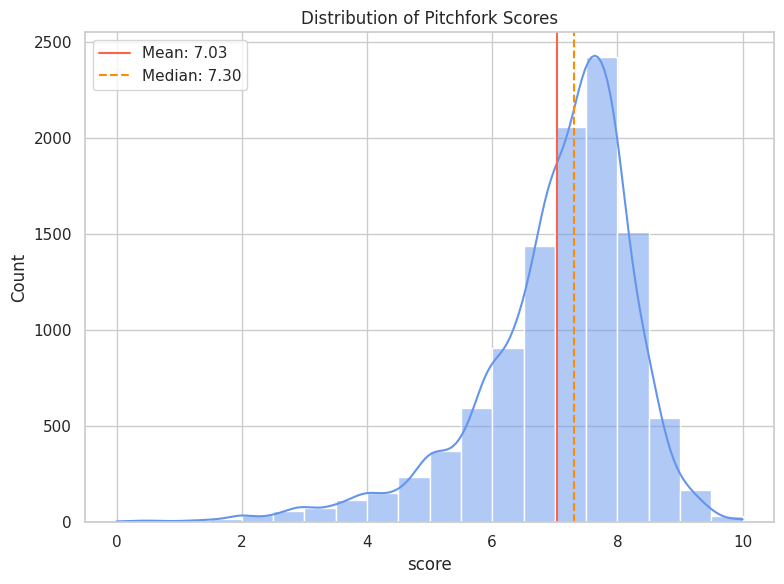

In [46]:
score = review_df['score']

plt.figure(figsize=(8, 6))

sns.histplot(score, bins=20, kde=True, color = 'cornflowerblue')
plt.axvline(score.mean(),
                color = 'tomato',
                linestyle = '-',
                label = f'Mean: {score.mean():.2f}')
plt.axvline(score.median(),
                color = 'darkorange',
                linestyle = '--',
                label = f'Median: {score.median():.2f}')
plt.title('Distribution of Pitchfork Scores')
plt.legend()

plt.tight_layout()
plt.show()

The distribution of the Pitchfork score is left-skewed, with a mean of 7.03, which is a bit lower than the median of 7.30.

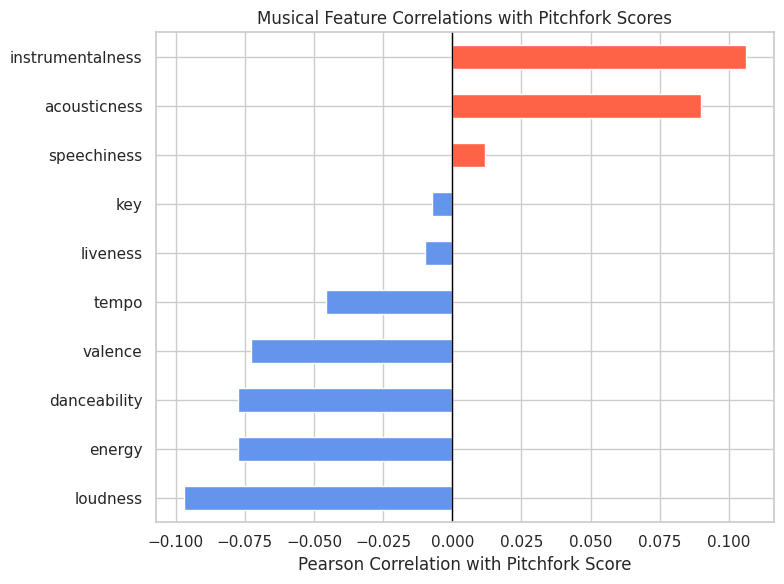

Feature correlations with Pitchfork Score:
loudness           -0.097
energy             -0.077
danceability       -0.077
valence            -0.073
tempo              -0.046
liveness           -0.010
key                -0.007
speechiness         0.012
acousticness        0.090
instrumentalness    0.106
Name: score, dtype: float64


In [47]:
cols = [
    'score',
    'genre',
    'reviewauthor',
    'releaseyear',
    'reviewdate',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

pitchfork_df = review_df[cols].copy()

score_correlations = (
    pitchfork_df.corr(numeric_only=True)['score']
    .drop(['score', 'releaseyear'])
    .sort_values()
)

plt.figure(figsize=(8, 6))

colors = [
    'cornflowerblue' if value < 0 else 'tomato'
    for value in score_correlations
]

score_correlations.plot(
    kind="barh",
    color=colors
)

plt.axvline(0, color = 'black', linewidth = 1)
plt.xlabel('Pearson Correlation with Pitchfork Score')
plt.title('Musical Feature Correlations with Pitchfork Scores')
plt.tight_layout()
plt.show()

print('Feature correlations with Pitchfork Score:')
print(score_correlations.round(3))

The Pearson Correlation scores between the Spotify audio features and the Pitchfork scores indicate that there seems to be a very weak relation between them. However, different audio features correlate differently with the Pitchfork scores, ranging from positive to negative correlations.

### Groupby Genre

In this section, we explore the Pitchfork scores based on the genre of the album.

In [48]:
genre_summary = (
    pitchfork_df.groupby('genre')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values("mean", ascending=False)
)

In [49]:
genre_summary

,mean,std,min,median,max,count
genre,,,,,,
Jazz,7.409,1.117,3.0,7.6,10.0,144
Experimental,7.402,1.058,0.3,7.6,10.0,987
Global,7.336,1.041,2.2,7.6,9.0,81
Folk/Country,7.290,1.048,2.3,7.5,10.0,403
Metal,7.101,1.196,0.8,7.4,9.0,569
Rap,7.053,1.298,1.6,7.3,10.0,674
Pop/R&B,7.019,1.108,2.0,7.2,10.0,653
Unknown,6.989,1.122,0.4,7.2,9.7,627
Rock,6.951,1.315,0.0,7.2,10.0,4042


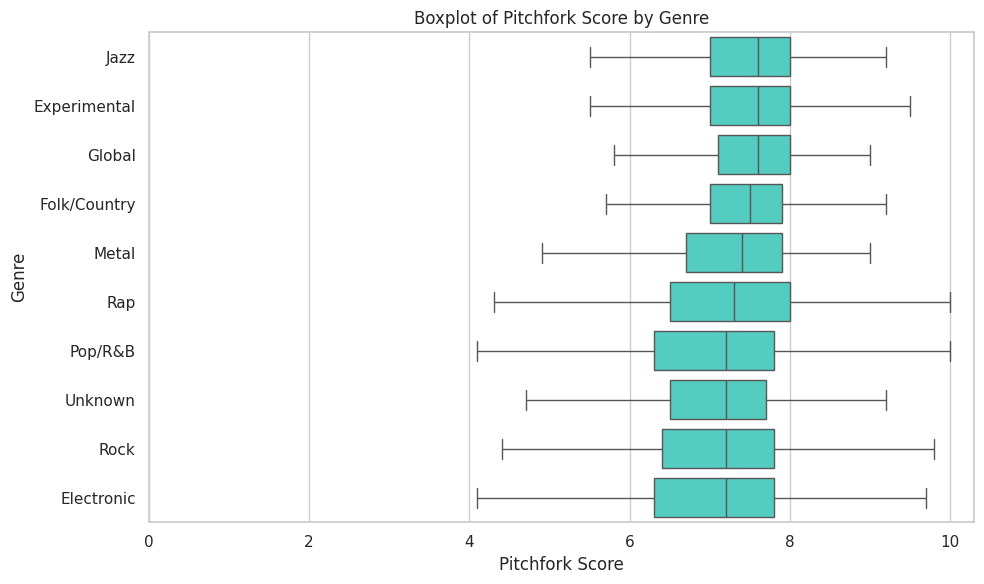

In [50]:
plt.figure(figsize=(10, 6))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'genre',
    order = genre_summary.sort_values("median", ascending=False).index,
    color = 'turquoise',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Pitchfork Score by Genre')
plt.xlabel('Pitchfork Score')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

The boxplot shows that the distribution of the Pitchfork scores differs between different genres. The median score of Jazz, Experimental, and Global music are about 0.5 points greater than Pop, Unknown, Rock, and Electronic music. Furthurmore, the spread of Pop and Rap genres are very large, compared to Gobal and Folk music.

### Groupby Review Date

Next, we explore the Pitchfork scores based on the year that the review was released.

In [51]:
(pitchfork_df['reviewdate'].dt.year - pitchfork_df['releaseyear'] > 1).sum()

np.int64(13)

There 13 reviews that are retroactive, where the review year is more than one year after the release year. This shows that almost all of the albums were reviewed around the time it was released.

In [52]:
rdate_summary = (
    pitchfork_df.groupby(pitchfork_df['reviewdate'].dt.year)['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

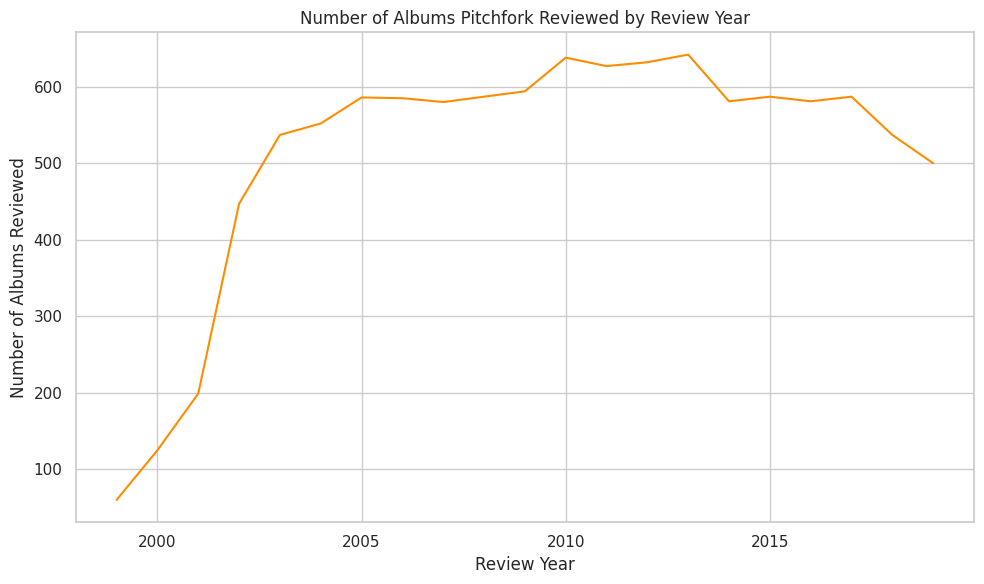

In [53]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'count',
    color = 'darkorange'
)
plt.xlim(left = 1998)
plt.xticks(range(2000, 2020, 5))
plt.title('Number of Albums Pitchfork Reviewed by Review Year')
plt.xlabel('Review Year')
plt.ylabel('Number of Albums Reviewed')

plt.tight_layout()
plt.show()

This graph shows the number of albums Pitchfork reviewed per year, starting from 1999. From 1999 to 2002, the number of albums reviewed per year increased dramatically. From 2003 to 2019, the number of albums reviewed fluctuates slightly, but stayed above 500 reviews per year.

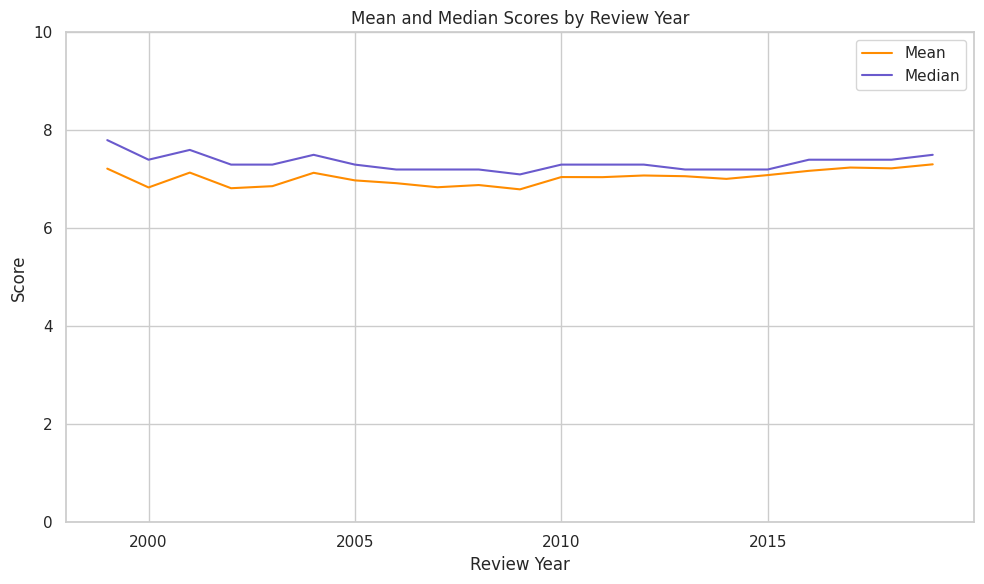

In [54]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'mean',
    color = 'darkorange',
    label='Mean'
)
sns.lineplot(
    data = rdate_summary,
    x = 'reviewdate',
    y = 'median',
    color = 'slateblue',
    label='Median'
)
plt.xlim(left = 1998)
plt.xticks(range(2000, 2020, 5))
plt.ylim(0, 10)
plt.title('Mean and Median Scores by Review Year')
plt.xlabel('Review Year')
plt.ylabel('Score')

plt.tight_layout()
plt.show()

This graph shows that the mean and median Pitchfork scores did not vary too much throughout the year. However, it looks like the scores are less left-skewed as time goes on. In the early 2000s, the difference beetween mean and median are pretty large, with mean being much lower than the median. In 2019, the difference between them is much smaller.

In [55]:
bins = [1999, 2005, 2010, 2015, 2020]
labels = ['1999-2004', '2005-2009', '2010-2014', '2015-2019']

pitchfork_df['years_bin'] = pd.cut(
    pitchfork_df['reviewdate'].dt.year,
    bins = bins,
    labels = labels,
    right = False
)

In [56]:
rdate_bin_summary = (
    pitchfork_df.groupby('years_bin', observed=True)['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

In [57]:
rdate_bin_summary

,mean,std,min,median,max,count
years_bin,,,,,,
1999-2004,6.967,1.616,0.0,7.4,10.0,1920
2005-2009,6.883,1.371,0.0,7.2,10.0,2932
2010-2014,7.049,1.093,1.0,7.3,10.0,3120
2015-2019,7.202,0.940,1.6,7.4,10.0,2792


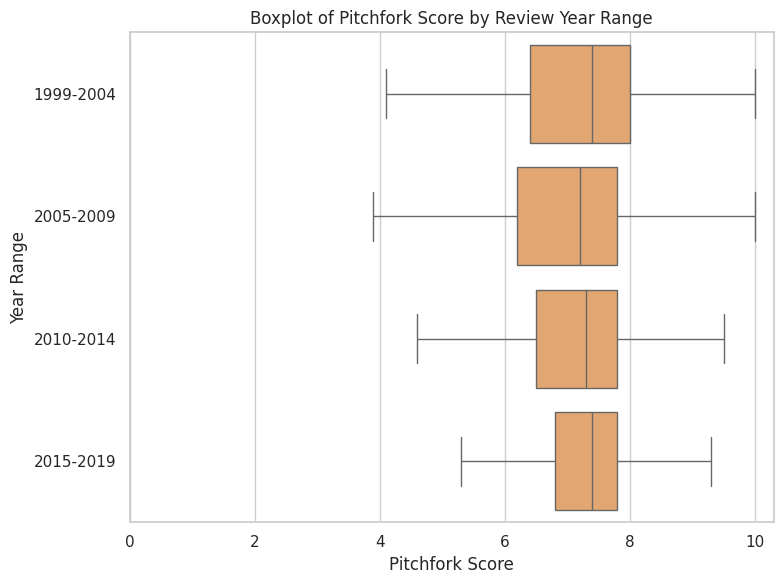

In [58]:
plt.figure(figsize=(8, 6))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'years_bin',
    order = rdate_bin_summary.index,
    color = 'sandybrown',
    orient ='h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Pitchfork Score by Review Year Range')
plt.xlabel('Pitchfork Score')
plt.ylabel('Year Range')
plt.tight_layout()
plt.show()

Here we group years into year ranges of around half a decade to not overwhelm the comparisons. The trend of tighter distribution as discovered earlier is much more apparent here, with the width of the boxplots noticeably getting shorter. Additionally, there seems to be a small trend of median scores improving from 2005 to 2019.

### Groupby Reviewer

Next, we will explore Pitchfork scores based on the reviewers.

In [59]:
reviewer_summary = (
    pitchfork_df.groupby('reviewauthor')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values('count', ascending = False)
)

reviewer_summary.head(15).round(3)

,mean,std,min,median,max,count
reviewauthor,,,,,,
Ian Cohen,6.482,1.488,0.2,6.6,9.3,462
Stephen M. Deusner,6.796,1.351,2.1,7.2,9.6,333
Joe Tangari,7.317,0.846,3.5,7.5,8.9,331
Mark Richardson,7.562,1.190,2.5,7.8,10.0,324
Stuart Berman,7.110,0.966,1.0,7.3,9.2,324
Brian Howe,7.121,0.895,2.8,7.4,9.0,260
Philip Sherburne,7.476,0.734,4.0,7.6,9.1,245
Marc Hogan,6.583,1.537,1.2,6.8,9.2,236
Nate Patrin,7.048,1.149,2.8,7.3,9.2,197


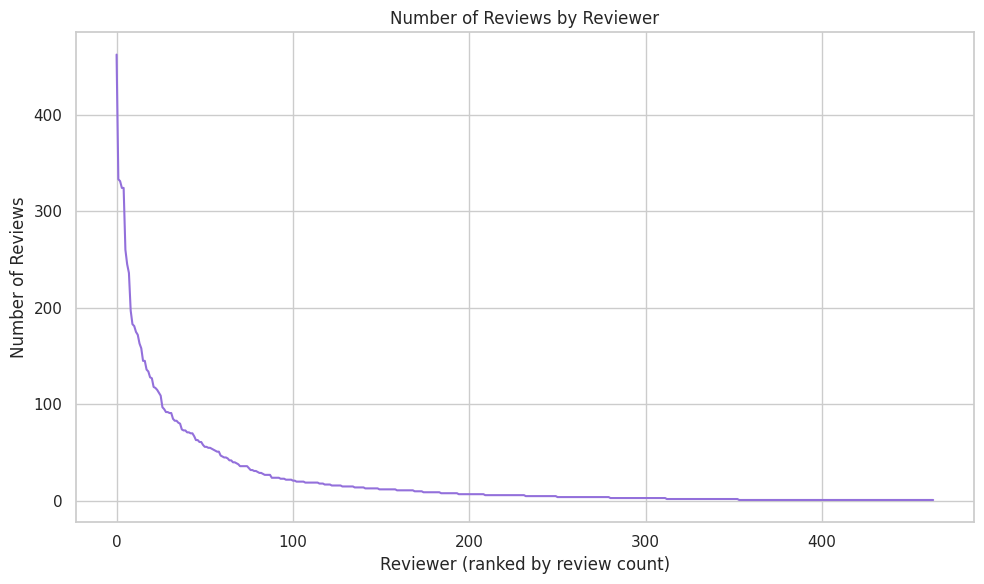

In [60]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = reviewer_summary,
    x = range(len(reviewer_summary)),
    y = "count",
    color = "mediumpurple"
)

plt.title('Number of Reviews by Reviewer')
plt.xlabel('Reviewer (ranked by review count)')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

This log curve shows that a few reviewer accounts for a large number of the reviews, with most reviewers only writing a few reviews.

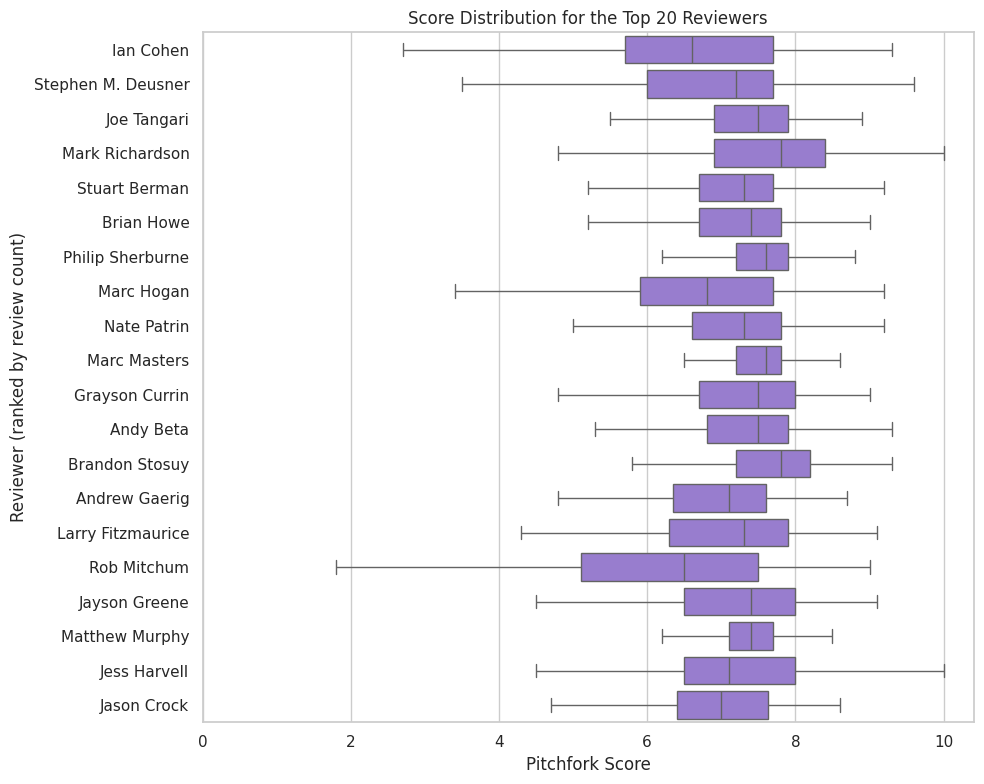

In [61]:
top20_reviewers = reviewer_summary.head(20).index

top20_df = review_df[
    review_df['reviewauthor'].isin(top20_reviewers)
]

plt.figure(figsize=(10, 8))
sns.boxplot(
    data = top20_df,
    x = 'score',
    y = 'reviewauthor',
    order = top20_reviewers,
    color = 'mediumpurple',
    orient = 'h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Score Distribution for the Top 20 Reviewers')
plt.xlabel('Pitchfork Score')
plt.ylabel('Reviewer (ranked by review count)')

plt.tight_layout()
plt.show()

This plot shows the score distributions given by the top 20 reviewers, each having more than 100 reviews. The distributions vary considerably. There's Joe Tangari and Matthew Murphy with very small distributions, and then there's Ian Cohan and Rob Mitchum with very wide distributions.

## EDA Discogs Ratings

In this section, we will explore the Discogs data that we scraped.

### Overall Discogs Rating statistics

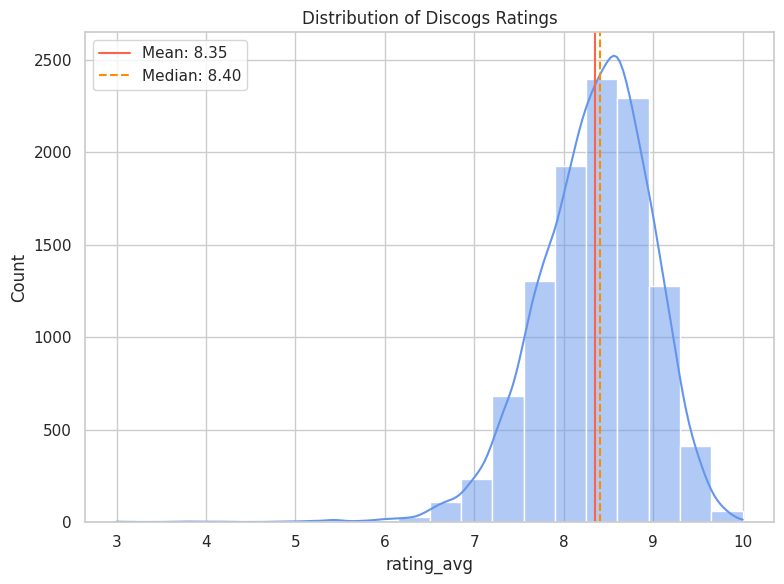

In [62]:
rating = review_df['rating_avg'] * 2

plt.figure(figsize=(8, 6))

sns.histplot(rating, bins=20, kde=True, color = 'cornflowerblue')
plt.axvline(rating.mean(),
                color = 'tomato',
                linestyle = '-',
                label = f'Mean: {rating.mean():.2f}')
plt.axvline(rating.median(),
                color = 'darkorange',
                linestyle = '--',
                label = f'Median: {rating.median():.2f}')
plt.title('Distribution of Discogs Ratings')
plt.legend()

plt.tight_layout()
plt.show()

We multiplied the Discogs rating averages by 2, since it is on a 0-5 scale, to make it comparable to the Pitchfork score of 0-10 scale. The distribution of average Discogs ratings is slightly left-skewed, with a mean of 8.35, a tiny bit lower than the median of 8.40. The Discogs ratings are considerably more normally distributed than the Pitchfork scores.

In [63]:
cols = [
    'rating_avg',
    'rating_count',
    'genre',
    'releaseyear',
    'danceability',
    'energy',
    'key',
    'loudness',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence',
    'tempo'
]

discogs_df = review_df[cols].copy()

In [64]:
discogs_df['rating_avg'] = discogs_df['rating_avg'] * 2

### Bin by Rating_count

Next, we will explore Discogs ratings based on the rating counts.

In [65]:
discogs_df['rating_count'].max()

9667.0

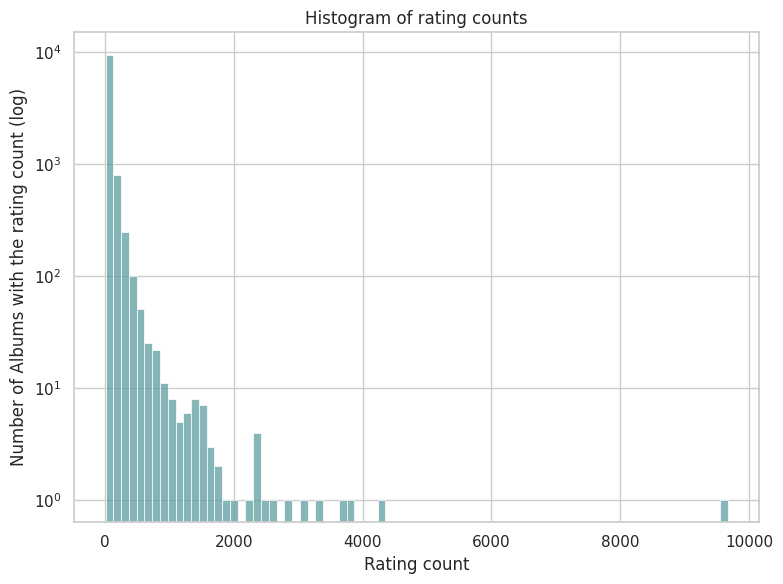

In [66]:
plt.figure(figsize=(8, 6))
sns.histplot(discogs_df["rating_count"], bins = 80, color = 'cadetblue')
plt.yscale("log")
plt.xlabel("Rating count")
plt.ylabel("Number of Albums with the rating count (log)")
plt.title("Histogram of rating counts")

plt.tight_layout()
plt.show()

The rating count of the albums also follow a log curve, with most albums having very low rating counts and some outliars of the albums that are extremely popular having much higher rating counts.

In [67]:
discogs_df["counts_bin"], bins = pd.qcut(discogs_df["rating_count"], 5, labels=False, retbins = True)
bins

array([  10. ,   16. ,   26.2,   45. ,   88. , 9667. ])

In [68]:
bins_summary = (
    discogs_df.groupby('counts_bin')['rating_avg']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_values('counts_bin', ascending = True)
)

bins_summary.round(3)

,mean,std,min,median,max,count
counts_bin,,,,,,
0,8.186,0.752,3.00,8.20,10.00,2207
1,8.292,0.630,4.82,8.34,10.00,2099
2,8.337,0.599,4.12,8.38,9.86,2182
3,8.402,0.541,6.20,8.44,9.82,2129
4,8.529,0.521,6.00,8.60,9.78,2147


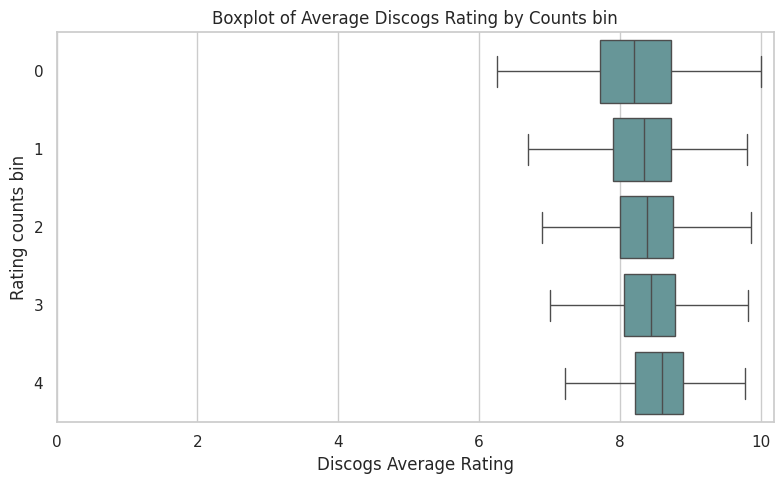

In [69]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data = discogs_df,
    x = 'rating_avg',
    y = 'counts_bin',
    order = bins_summary.index,
    color = 'cadetblue',
    orient = 'h',
    showfliers = False
)
plt.xlim(left = 0)
plt.title('Boxplot of Average Discogs Rating by Counts bin')
plt.xlabel('Discogs Average Rating')
plt.ylabel('Rating counts bin')
plt.tight_layout()
plt.show()

We divide the ratings into 5 equally sized bins: \
bin 0: 10-16 rating counts,\
bin 1: 17-26 rating counts, \
bin 2: 27-45 rating counts, \
bin 3: 45-88 rating counts, \
bin 4: 89-9667 rating counts.

The rating distributions get tighter as the number of reviews go up and the median rating also shifts right, to a higher ratings.

## Musicality UMAP

We also conducted a quick UMAP to visualize the clustering of the album genre based on the spotify audio features.

In [70]:
top_5_genre = review_df['genre'].value_counts().head(5).index

review_filtered = review_df[review_df['genre'].isin(top_5_genre)]

In [71]:
reducer = umap.UMAP(random_state = 424)

review_data = review_filtered[
    [
    "danceability", "energy", "key", "loudness", "speechiness",
    "acousticness", "instrumentalness", "liveness", "valence", "tempo"
    ]
].values

scaled_review_data = StandardScaler().fit_transform(review_data)

In [34]:
embedding = reducer.fit_transform(scaled_review_data)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


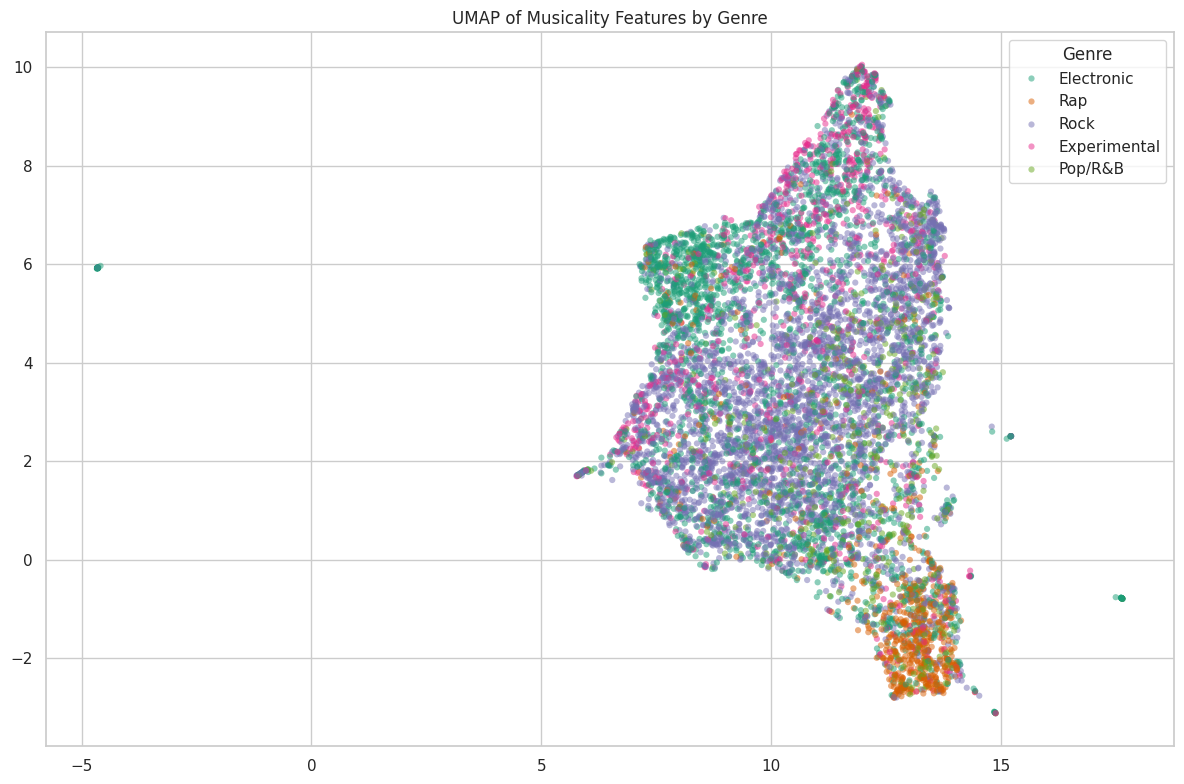

In [35]:
plt.figure(figsize=(12, 8))

sns.scatterplot(
    x = embedding[:, 0],
    y = embedding[:, 1],
    hue = review_filtered['genre'],
    alpha = 0.5,
    s = 20,
    linewidth = 0,
    palette = 'Dark2'
)

plt.title('UMAP of Musicality Features by Genre')
plt.legend(
    title = 'Genre',
    loc = 'upper right'
)

plt.tight_layout()
plt.show()

Due to the number of genres and data points, we chose to only look at the top 5 genres instead of 10 that was in the dataset. Overall, it looks like some genres are more clustered, specifically Rap. Whereas Rock does not show strong signs of clustering.

## Preliminary Comparison

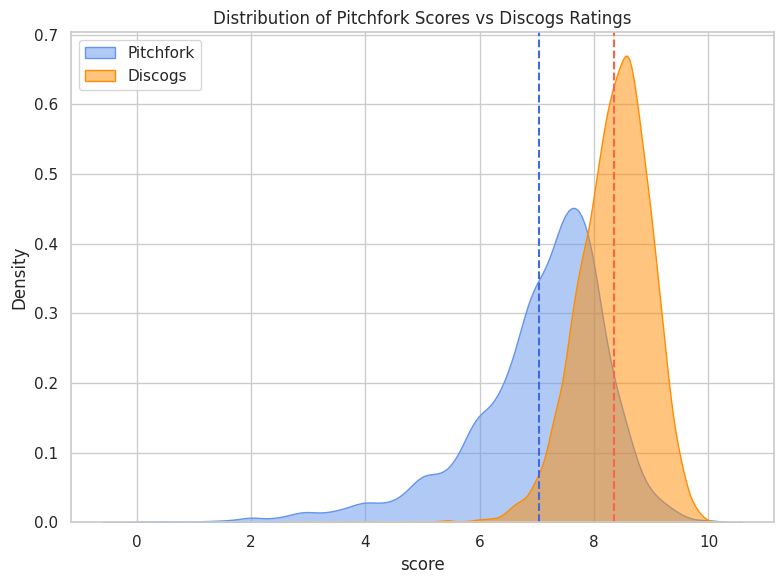

In [89]:
plt.figure(figsize=(8, 6))

sns.kdeplot(score, color = 'cornflowerblue', fill = True, alpha = 0.5, label = 'Pitchfork')
plt.axvline(score.mean(),
                color = 'royalblue',
                linestyle = '--')
sns.kdeplot(rating, color = 'darkorange', fill = True, alpha = 0.5, label = 'Discogs')
plt.axvline(rating.mean(),
                color = 'tomato',
                linestyle = '--')

plt.title('Distribution of Pitchfork Scores vs Discogs Ratings')
plt.legend(loc='upper left')

plt.tight_layout()
plt.show()

In [119]:
genre_separated = {}

for genre, group in review_df.groupby("genre"):
  genre_separated[genre] = group[['score', 'rating_avg']].copy()

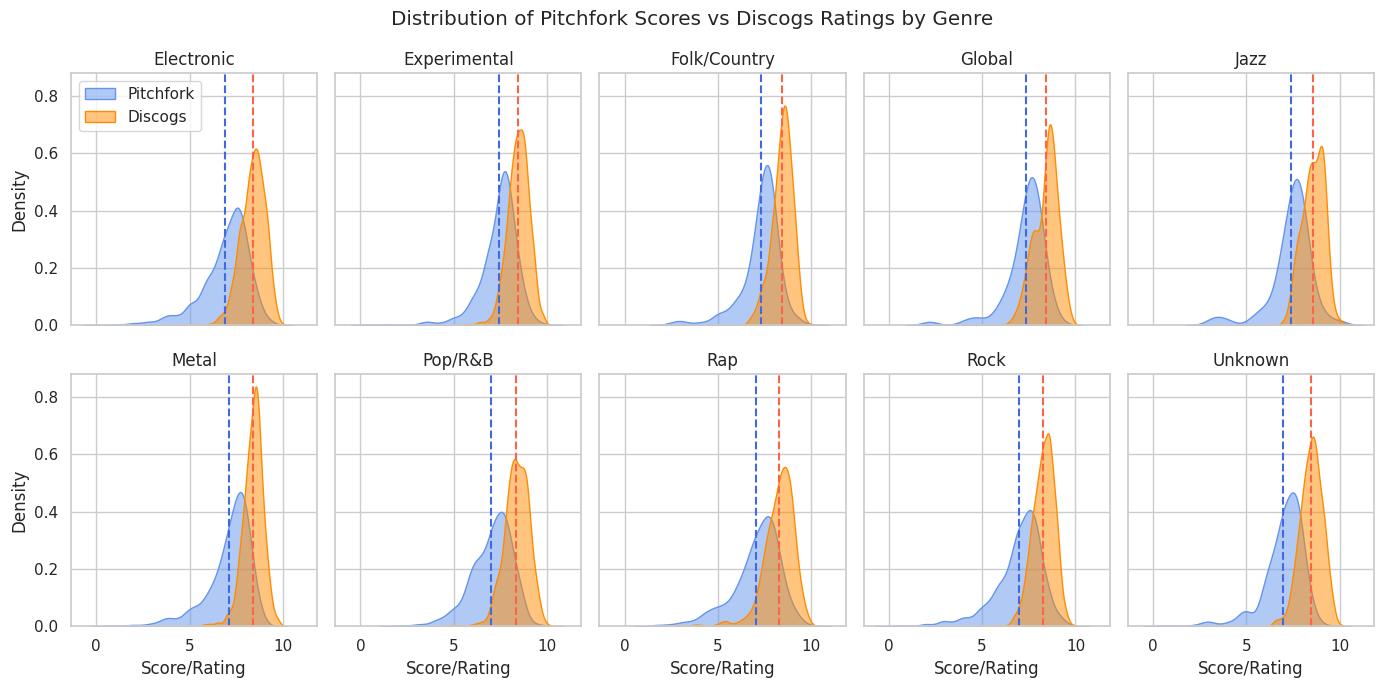

In [161]:
fig, axes = plt.subplots(2, 5, figsize=(14, 7), sharex=True, sharey=True)
for ax, gen, col in zip(axes.flatten(), genre_separated.keys(), genre_separated.values()):
    sns.kdeplot(col['score'], color = 'cornflowerblue', fill = True, alpha = 0.5, label = 'Pitchfork', ax = ax)
    ax.axvline(col['score'].mean(),
                color = 'royalblue',
                linestyle = '--')
    sns.kdeplot(col['rating_avg']*2, color = 'darkorange', fill = True, alpha = 0.5, label = 'Discogs', ax = ax)
    ax.axvline(col['rating_avg'].mean()*2,
                color = 'tomato',
                linestyle = '--')
    ax.set_title(gen)
    ax.set_xlabel('Score/Rating')
    if gen == 'Electronic':
      ax.legend(loc = 'upper left')
fig.suptitle('Distribution of Pitchfork Scores vs Discogs Ratings by Genre')
fig.tight_layout()
plt.show()

# Code Graveyard (potential for reuse)

### Groupby Release Year

In [37]:
year_summary = (
    pitchfork_df.groupby('releaseyear')['score']
    .agg(['mean', 'std', 'min', 'median', 'max', 'count'])
    .round(3)
    .sort_index()
)

In [38]:
year_summary

,mean,std,min,median,max,count
releaseyear,,,,,,
1998.0,5.650,0.778,5.1,5.65,6.2,2
1999.0,7.152,2.017,0.3,7.80,10.0,58
2000.0,6.905,2.046,0.0,7.50,10.0,115
2001.0,7.004,1.723,0.4,7.50,9.7,278
2002.0,6.808,1.643,0.5,7.20,10.0,474
2003.0,6.889,1.630,0.0,7.30,10.0,513
2004.0,7.185,1.258,2.1,7.50,9.7,516
2005.0,6.974,1.408,0.4,7.30,9.6,594
2006.0,6.895,1.342,0.0,7.20,9.4,572


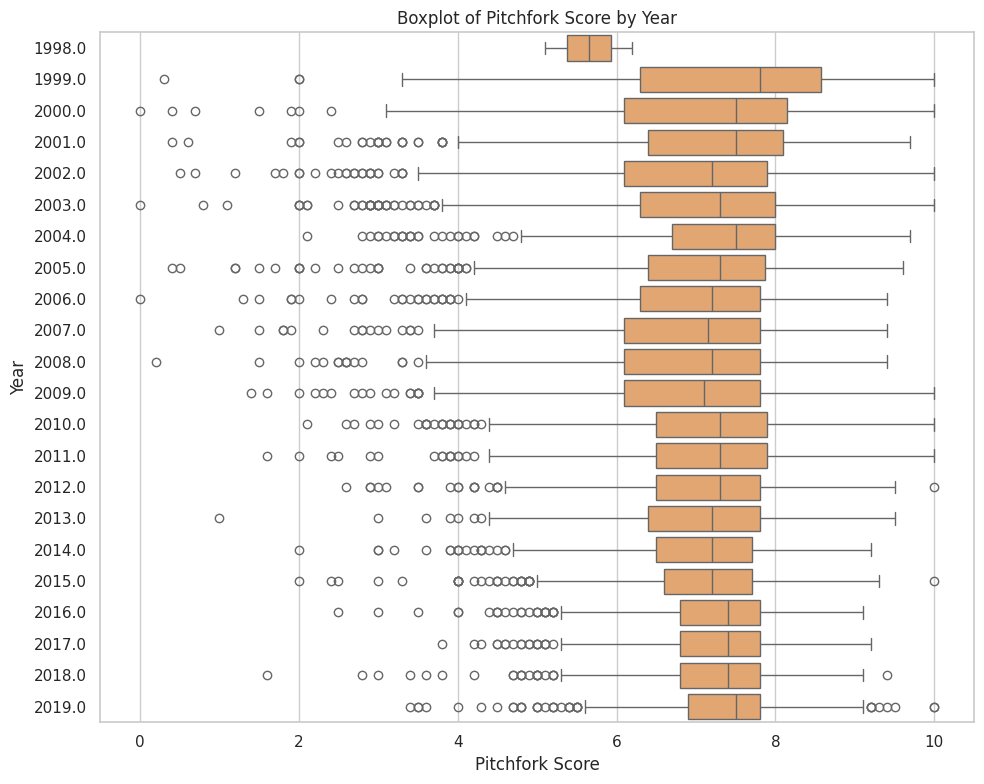

In [39]:
plt.figure(figsize=(10, 8))
sns.boxplot(
    data = pitchfork_df,
    x = 'score',
    y = 'releaseyear',
    order = year_summary.index,
    color = 'sandybrown',
    orient ='h'
)
plt.title('Boxplot of Pitchfork Score by Year')
plt.xlabel('Pitchfork Score')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

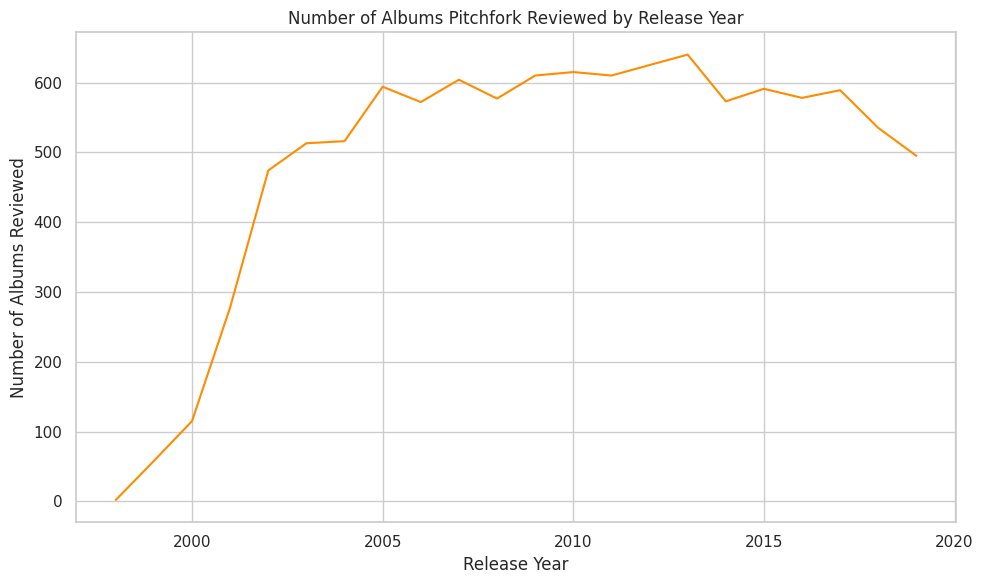

In [40]:
plt.figure(figsize=(10, 6))
sns.lineplot(
    data = year_summary,
    x = 'releaseyear',
    y = 'count',
    color = 'darkorange'
)
plt.title('Number of Albums Pitchfork Reviewed by Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Albums Reviewed')

plt.tight_layout()
plt.show()